<a href="https://colab.research.google.com/github/luiscalvi/CSC349/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Luis Calvillo ---  Assignment 6

Task 1: Dataset Loading and Dimensionality Inspection Load the Olivetti Faces dataset using sklearn.datasets.fetch_olivetti_faces. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.

The dataset we have contains 400 grayscale images of 40 different people. Each image is represented by 4,096 features making the dataset high dimensional. Here it loads the dataset, displays its dimensions, and visualizes 20 sample faces with their respective IDs.

Total number of samples: 400
Number of unique subjects: 40
Number of features: 4096
Image dimensions: (64, 64)


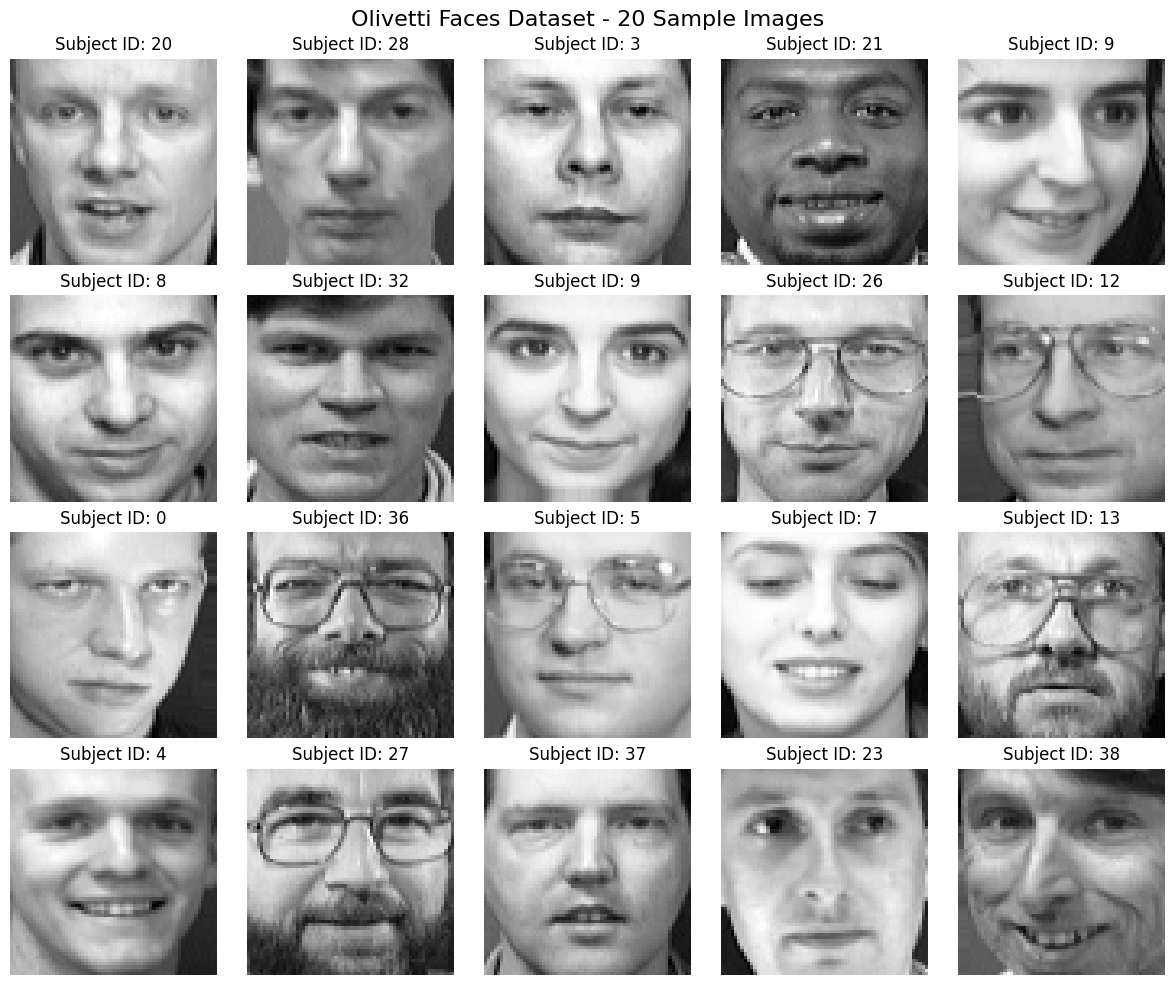

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Load the Olivetti Faces dataset
faces = fetch_olivetti_faces()

# Separate image features, target labels, and images
X = faces.data
y = faces.target
images = faces.images

# Display dataset information
print("Total number of samples:", X.shape[0])
print("Number of unique subjects:", len(np.unique(y)))
print("Number of features:", X.shape[1])
print("Image dimensions:", images.shape[1:])

# Selects 20 random faces
np.random.seed(42)
sample_indices = np.random.choice(len(images), 20, replace=False)

# Creating a 4x5 grid of sample faces
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, index in zip(axes.flat, sample_indices):

    # Display each grayscale face
    ax.imshow(images[index], cmap="gray")

    # Label each face with its subject ID
    ax.set_title(f"Subject ID: {y[index]}")
    ax.axis("off")

plt.suptitle("Olivetti Faces Dataset - 20 Sample Images", fontsize=16)
plt.tight_layout()
plt.show()


Task 2: Cumulative Explained Variance & Elbow Plot Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.

PCA reduces the number of features while also perserving as much info. Here the task fits a PCA model to the Olivetti Faces dataset and plots the individual and cumulative explained variance. Determining how many principal components are needed to retain.

Components for 90% variance: 66
Components for 95% variance: 123
Components for 99% variance: 260


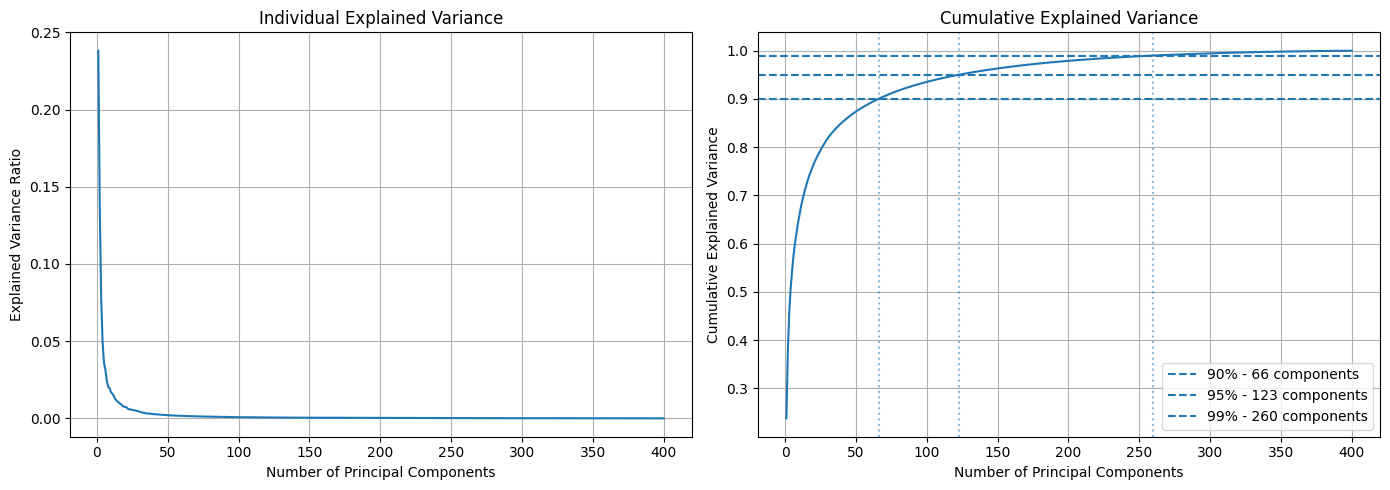

In [3]:

from sklearn.decomposition import PCA

# Fit PCA using all available components
pca = PCA()
pca.fit(X)

# Calculate individual and cumulative explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Finds components needed for 90%, 95%, and 99% variance
k_90 = np.searchsorted(cumulative_variance, 0.90) + 1
k_95 = np.searchsorted(cumulative_variance, 0.95) + 1
k_99 = np.searchsorted(cumulative_variance, 0.99) + 1

# Print component counts
print("Components for 90% variance:", k_90)
print("Components for 95% variance:", k_95)
print("Components for 99% variance:", k_99)

# Creates two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot individual explained variance
axes[0].plot(
    range(1, len(explained_variance) + 1),
    explained_variance
)
axes[0].set_title("Individual Explained Variance")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].grid(True)

# Plot cumulative explained variance
axes[1].plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

# Mark variance thresholds
for threshold, k in [(0.90, k_90), (0.95, k_95), (0.99, k_99)]:
    axes[1].axhline(y=threshold, linestyle="--",
                    label=f"{int(threshold * 100)}% - {k} components")
    axes[1].axvline(x=k, linestyle=":", alpha=0.5)

axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Task 3: Image Compression and Reconstruction Analysis Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

Here the task uses PCA to compress & reconstruct 5 images using different values 10-300. Comparing the reconstructed images with the originals, to show how image quality improves as more components are retained. We also calculated the mean squared error to measure how much information is lost during compression

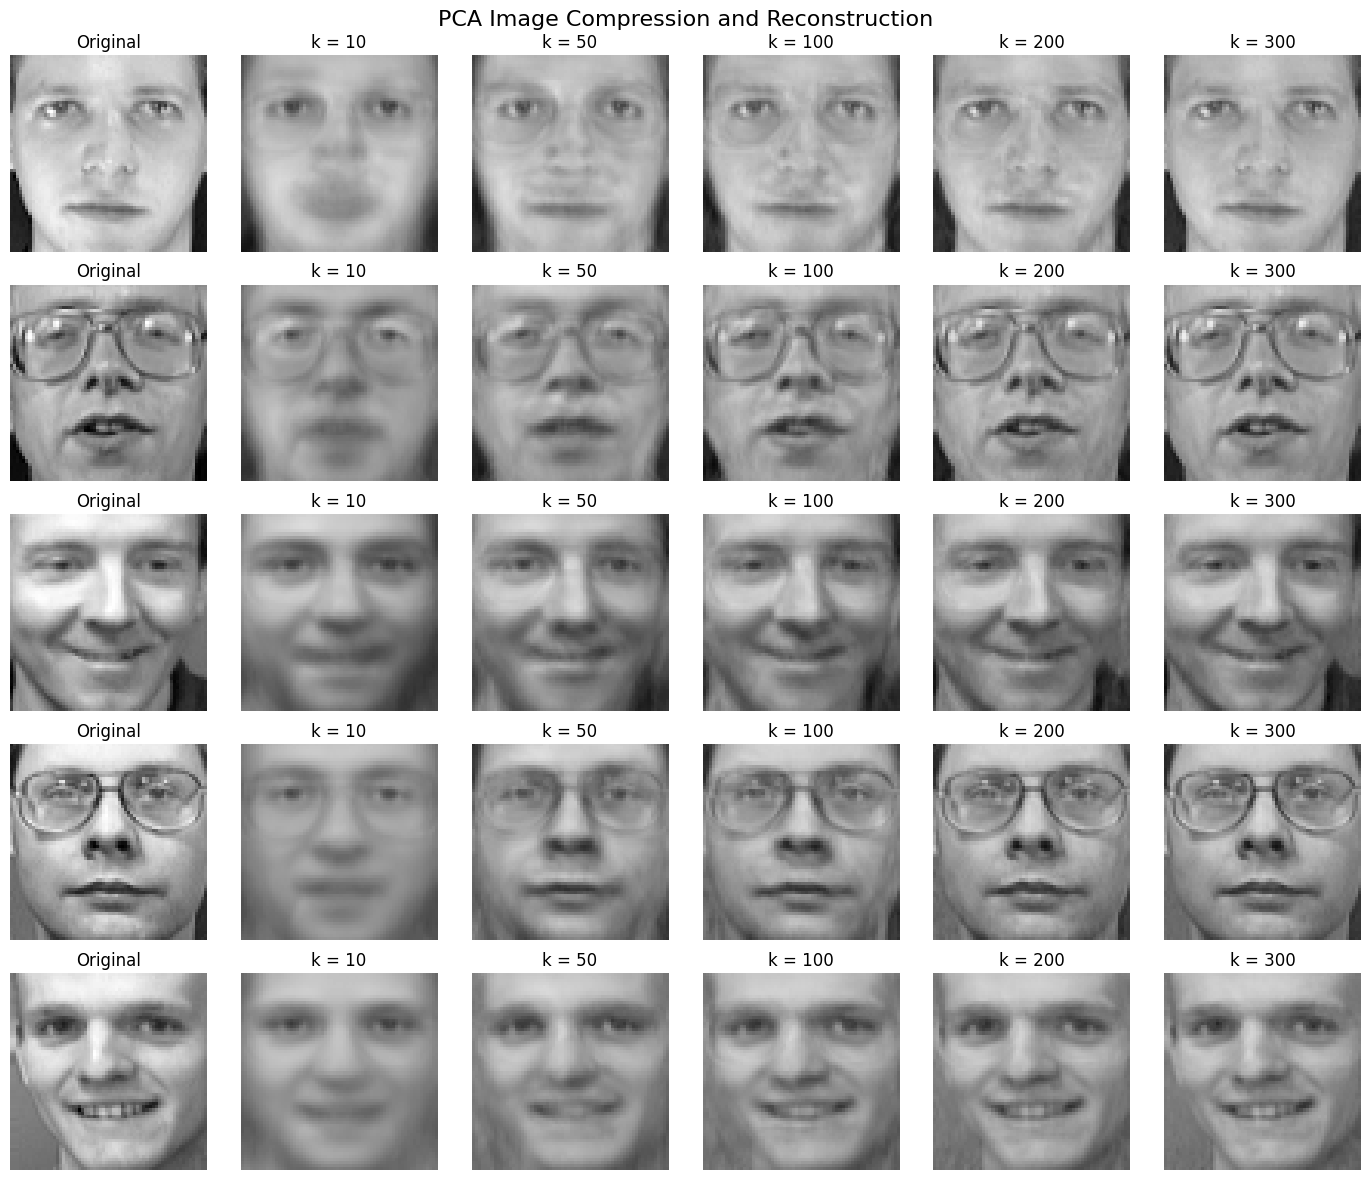

Components: 10, MSE: 0.005665
Components: 50, MSE: 0.002380
Components: 100, MSE: 0.001312
Components: 200, MSE: 0.000386
Components: 300, MSE: 0.000112


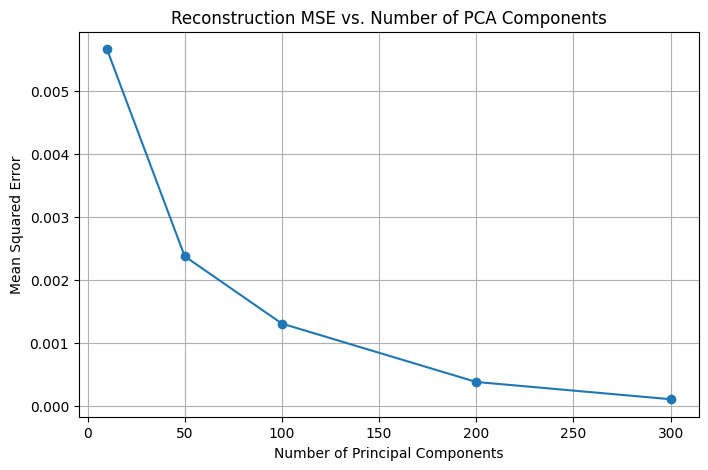

In [4]:

from sklearn.metrics import mean_squared_error

# Select 5 representative facial images
sample_indices = [0, 10, 20, 30, 40]
original_faces = X[sample_indices]

# Define the number of PCA components
components = [10, 50, 100, 200, 300]

# Store reconstruction errors
mse_values = []

# Create a grid for original and reconstructed faces
fig, axes = plt.subplots(5, 6, figsize=(14, 12))

for i, face in enumerate(original_faces):
    # Display the original face
    axes[i, 0].imshow(face.reshape(64, 64), cmap="gray")
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")

    for j, k in enumerate(components):
        # Compress using the first k principal components
        compressed = pca.transform(face.reshape(1, -1))[:, :k]

        # Reconstruct the face from compressed features
        reconstructed = compressed @ pca.components_[:k, :] + pca.mean_

        # Display the reconstructed image
        axes[i, j + 1].imshow(
            reconstructed.reshape(64, 64),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[i, j + 1].set_title(f"k = {k}")
        axes[i, j + 1].axis("off")

plt.suptitle("PCA Image Compression and Reconstruction", fontsize=16)
plt.tight_layout()
plt.show()

# Calculate average MSE for each component threshold
for k in components:
    # Compress the selected images
    compressed = pca.transform(original_faces)[:, :k]

    # Reconstruct the images
    reconstructed = compressed @ pca.components_[:k, :] + pca.mean_

    # Calculate reconstruction error
    mse = mean_squared_error(original_faces, reconstructed)
    mse_values.append(mse)

    print(f"Components: {k}, MSE: {mse:.6f}")

# Plot MSE against the number of components
plt.figure(figsize=(8, 5))
plt.plot(components, mse_values, marker="o")

plt.title("Reconstruction MSE vs. Number of PCA Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()


Task 4: Visualization of "Eigenfaces" Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5  plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.

Here the task visualizes the first 15 principal components from the PCA model. Each one represents an important pattern like lighting, facial structure, and differences in facial features. The percentage of variance explained by each component is displayed to show how much information it captures.

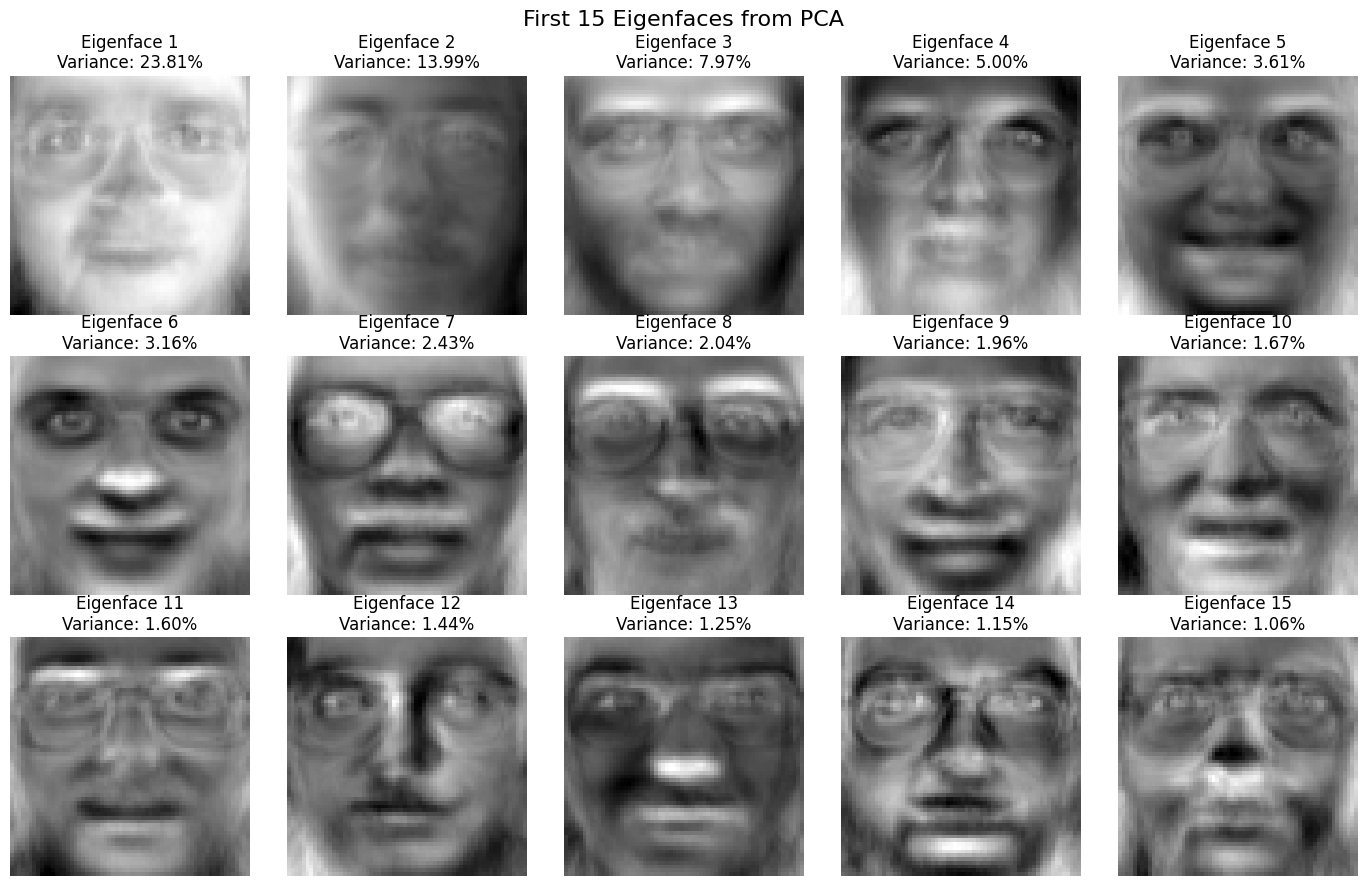

In [5]:

# Extract the first 15 principal components
eigenfaces = pca.components_[:15]

# Get the explained variance ratio for each component
variance_ratios = pca.explained_variance_ratio_[:15]

# Create a 3x5 grid to display eigenfaces
fig, axes = plt.subplots(3, 5, figsize=(14, 9))

for i, ax in enumerate(axes.flat):
    # Reshape each principal component into a 64x64 image
    eigenface = eigenfaces[i].reshape(64, 64)

    # Display the eigenface
    ax.imshow(eigenface, cmap="gray")

    # Label each eigenface with its explained variance
    ax.set_title(
        f"Eigenface {i + 1}\nVariance: {variance_ratios[i] * 100:.2f}%"
    )

    ax.axis("off")

plt.suptitle("First 15 Eigenfaces from PCA", fontsize=16)
plt.tight_layout()
plt.show()


Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model) Perform a stratified train/test split (80/20). Train a LogisticRegression classifier on:

Here we compare the logistic regression using the original 4,096 features against PCA-reduced features.. The dataset is split into 80% training and 20% testing, with PCA fitted only on the training data to prevent data from leaking. Both models are evaluated using their test accuracy and training time to determine whether PCA improves efficiency while maintaining accuracy.


Original Features: 4096
PCA Features: 111

Logistic Regression (Raw Features)
Accuracy: 0.9625
Training Time: 33.4899 seconds

Logistic Regression (PCA Features)
Accuracy: 0.9625
Training Time: 0.7419 seconds


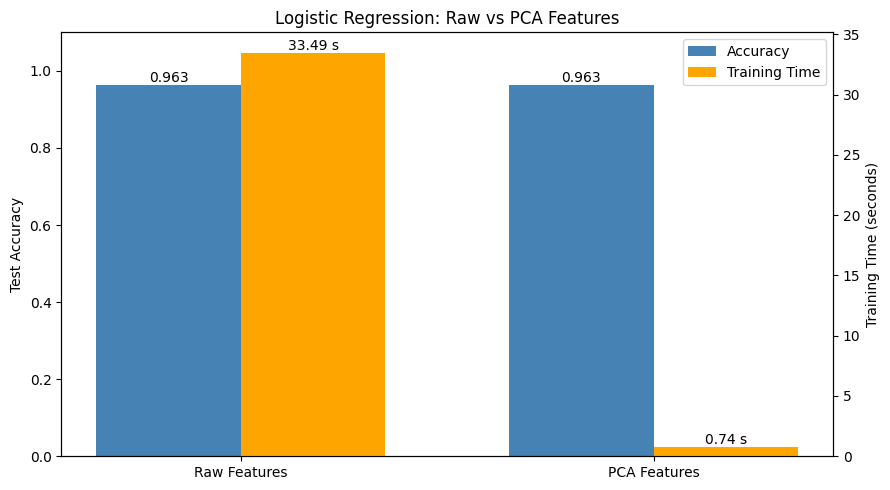

In [6]:

import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Model 1: Logistic Regression using raw features
clf_raw = LogisticRegression(max_iter=2000)

# Measure training time
start = time.perf_counter()
clf_raw.fit(X_train, y_train)
raw_time = time.perf_counter() - start

# Predict and calculate accuracy
raw_pred = clf_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, raw_pred)

# Model 2: PCA (95% variance) + Logistic Regression
# PCA is fitted only on the training set
pca_pipeline = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("logreg", LogisticRegression(max_iter=2000))
])

# Measure total PCA + classifier training time
start = time.perf_counter()
pca_pipeline.fit(X_train, y_train)
pca_time = time.perf_counter() - start

# Predict and calculate accuracy
pca_pred = pca_pipeline.predict(X_test)
pca_accuracy = accuracy_score(y_test, pca_pred)

# Save PCA features for Tasks 6 and 7
pca_95 = pca_pipeline.named_steps["pca"]
X_train_pca = pca_95.transform(X_train)
X_test_pca = pca_95.transform(X_test)

# Display results
print("Original Features:", X_train.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print("\nLogistic Regression (Raw Features)")
print(f"Accuracy: {raw_accuracy:.4f}")
print(f"Training Time: {raw_time:.4f} seconds")

print("\nLogistic Regression (PCA Features)")
print(f"Accuracy: {pca_accuracy:.4f}")
print(f"Training Time: {pca_time:.4f} seconds")

# Compare accuracy and training time
models = ["Raw Features", "PCA Features"]
accuracies = [raw_accuracy, pca_accuracy]
times = [raw_time, pca_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 5))

# Accuracy bars (left axis)
bars1 = ax1.bar(
    x - width/2, accuracies, width,
    color="steelblue", label="Accuracy"
)
ax1.set_ylabel("Test Accuracy")
ax1.set_ylim(0, 1.1)

# Training time bars (right axis)
ax2 = ax1.twinx()
bars2 = ax2.bar(
    x + width/2, times, width,
    color="orange", label="Training Time"
)
ax2.set_ylabel("Training Time (seconds)")

# Add labels and title
ax1.set_xticks(x)
ax1.set_xticklabels(models)
ax1.set_title("Logistic Regression: Raw vs PCA Features")

# Display values above bars
ax1.bar_label(bars1, fmt="%.3f")
ax2.bar_label(bars2, fmt="%.2f s")

# Combine legends
ax1.legend(
    [bars1, bars2],
    ["Accuracy", "Training Time"],
    loc="upper right"
)

plt.tight_layout()
plt.show()

Task 6: Non-Linear Classification (Kernel SVM) Train a SVC with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.

Task 6 trains a support vector classifier using an RBF kernel on the PCA-reduced features that preserve 95% of the variance. Unlike the last task, the RBF kernel can capture non-linear relationships between facial features, improving classification accuracy. The model's training time and accuracy are measured, and a confusion matrix is created to compare its predictions with the logistic regression baseline.


SVM with RBF Kernel (PCA Features)
Accuracy: 0.9750
Training Time: 0.0841 seconds

Classification Accuracy Comparison
Logistic Regression (PCA): 0.9625
SVM (RBF Kernel): 0.9750


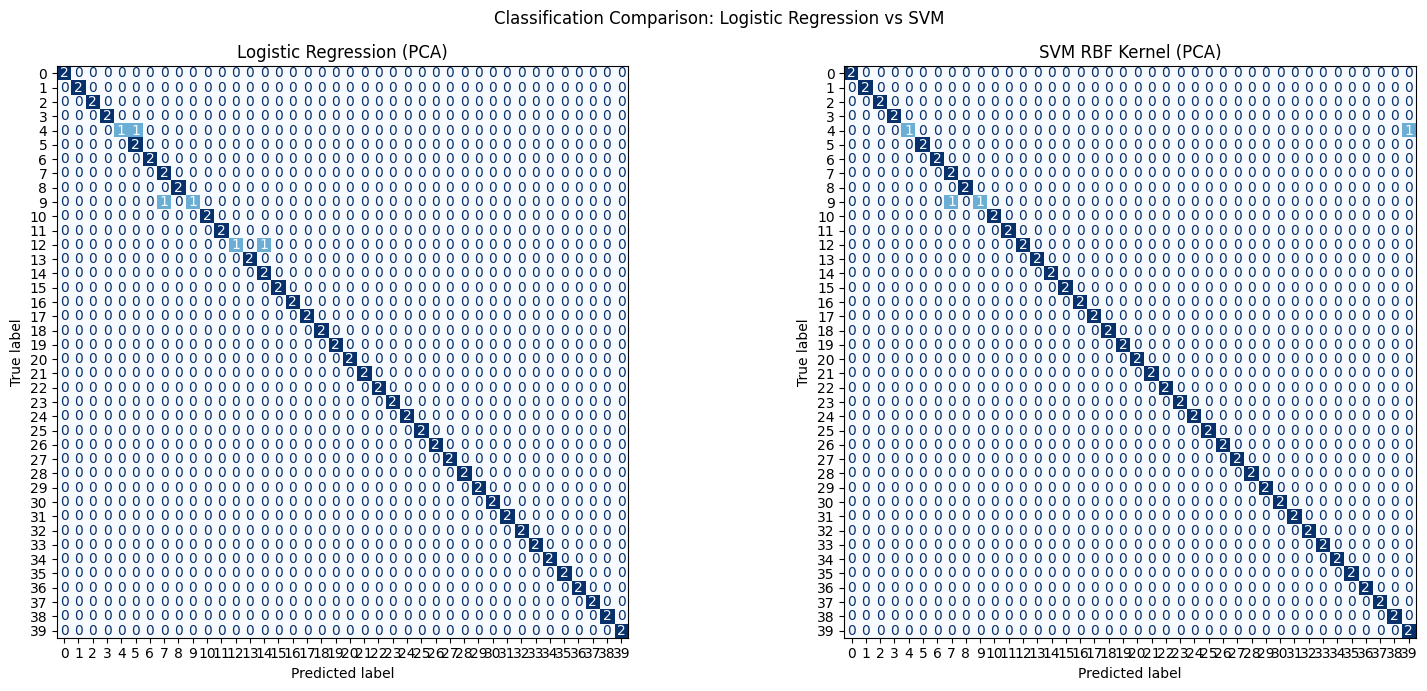

In [7]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Create SVM classifier with RBF kernel
svm_rbf = SVC(kernel="rbf", C=10, gamma="scale")

# Measure training time
start = time.perf_counter()
svm_rbf.fit(X_train_pca, y_train)
svm_time = time.perf_counter() - start

# Predict using PCA-reduced test features
svm_pred = svm_rbf.predict(X_test_pca)

# Calculate test accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM with RBF Kernel (PCA Features)")
print(f"Accuracy: {svm_accuracy:.4f}")
print(f"Training Time: {svm_time:.4f} seconds")

# Compare SVM against Logistic Regression
print("\nClassification Accuracy Comparison")
print(f"Logistic Regression (PCA): {pca_accuracy:.4f}")
print(f"SVM (RBF Kernel): {svm_accuracy:.4f}")

# Create confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, pca_pred,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Logistic Regression (PCA)")

# SVM confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)
axes[1].set_title("SVM RBF Kernel (PCA)")

plt.suptitle("Classification Comparison: Logistic Regression vs SVM")
plt.tight_layout()
plt.show()


Task 7: Ensemble Classification on PCA Features Construct a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.

Here we create a soft voting ensemble that combines three classifiers, a polynomial kernel SVM, an RBF Kernel SVM, and a random forest with 100 trees. It combines the predicted probabilities from each model to make a final classification decision. The ensemble is trained using PCA-reduced features, and its accuracy and training time are compared against Logistic Regression and the RBF SVM


Soft Voting Ensemble (PCA Features)
Accuracy: 0.9750
Training Time: 1.9316 seconds

Model Accuracy Comparison
Logistic Regression (Raw): 0.9625
Logistic Regression (PCA): 0.9625
SVM RBF (PCA): 0.9750
Soft Voting Ensemble (PCA): 0.9750


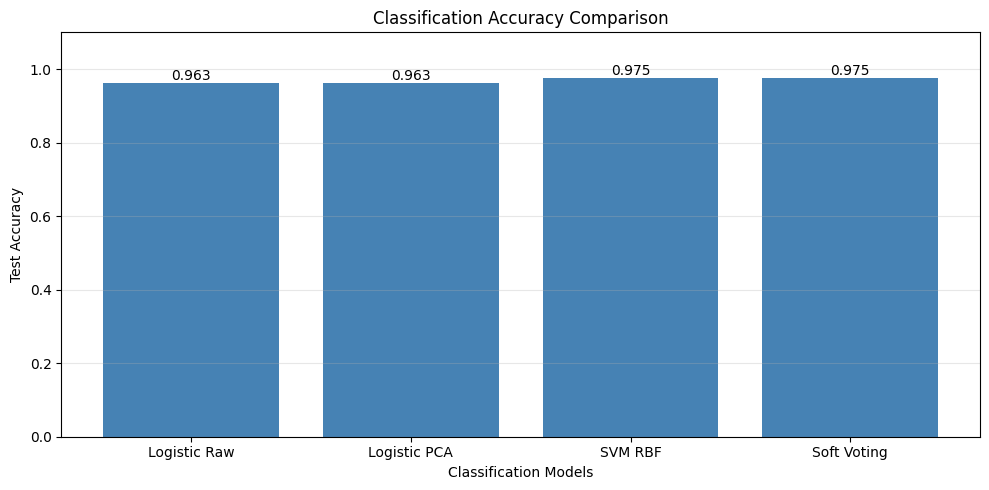

In [8]:

from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# Create the three classifiers
svm_poly = SVC(kernel="poly", degree=2, C=10, probability=True)

svm_rbf_ensemble = SVC(kernel="rbf", C=10, probability=True)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Create soft voting ensemble
voting_clf = VotingClassifier(
    estimators=[
        ("svm_poly", svm_poly),
        ("svm_rbf", svm_rbf_ensemble),
        ("random_forest", random_forest)
    ],
    voting="soft"
)

# Measure ensemble training time
start = time.perf_counter()
voting_clf.fit(X_train_pca, y_train)
ensemble_time = time.perf_counter() - start

# Predict using PCA-reduced test features
ensemble_pred = voting_clf.predict(X_test_pca)

# Calculate ensemble accuracy
ensemble_accuracy = accuracy_score(y_test, ensemble_pred)

print("Soft Voting Ensemble (PCA Features)")
print(f"Accuracy: {ensemble_accuracy:.4f}")
print(f"Training Time: {ensemble_time:.4f} seconds")

# Compare all models
print("\nModel Accuracy Comparison")
print(f"Logistic Regression (Raw): {raw_accuracy:.4f}")
print(f"Logistic Regression (PCA): {pca_accuracy:.4f}")
print(f"SVM RBF (PCA): {svm_accuracy:.4f}")
print(f"Soft Voting Ensemble (PCA): {ensemble_accuracy:.4f}")

# Plot accuracy comparison
models = [
    "Logistic Raw",
    "Logistic PCA",
    "SVM RBF",
    "Soft Voting"
]

accuracies = [
    raw_accuracy,
    pca_accuracy,
    svm_accuracy,
    ensemble_accuracy
]

plt.figure(figsize=(10, 5))

bars = plt.bar(models, accuracies, color="steelblue")

# Display accuracy values above bars
plt.bar_label(bars, fmt="%.3f")

plt.title("Classification Accuracy Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Task 8: Comprehensive Comparative Evaluation Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations:

The final task compares the accuracy and training time of all four classification models. A double axis bar chart displays the test accuracy on the left axis and training time on the right axis. This comparison helps determine which model provides the best balance between classification performance and computational efficiency.


Model Performance Comparison

Logistic Raw
Accuracy: 0.9625
Training Time: 33.4899 seconds

Logistic PCA
Accuracy: 0.9625
Training Time: 0.7419 seconds

SVM RBF
Accuracy: 0.9750
Training Time: 0.0841 seconds

Soft Voting
Accuracy: 0.9750
Training Time: 1.9316 seconds



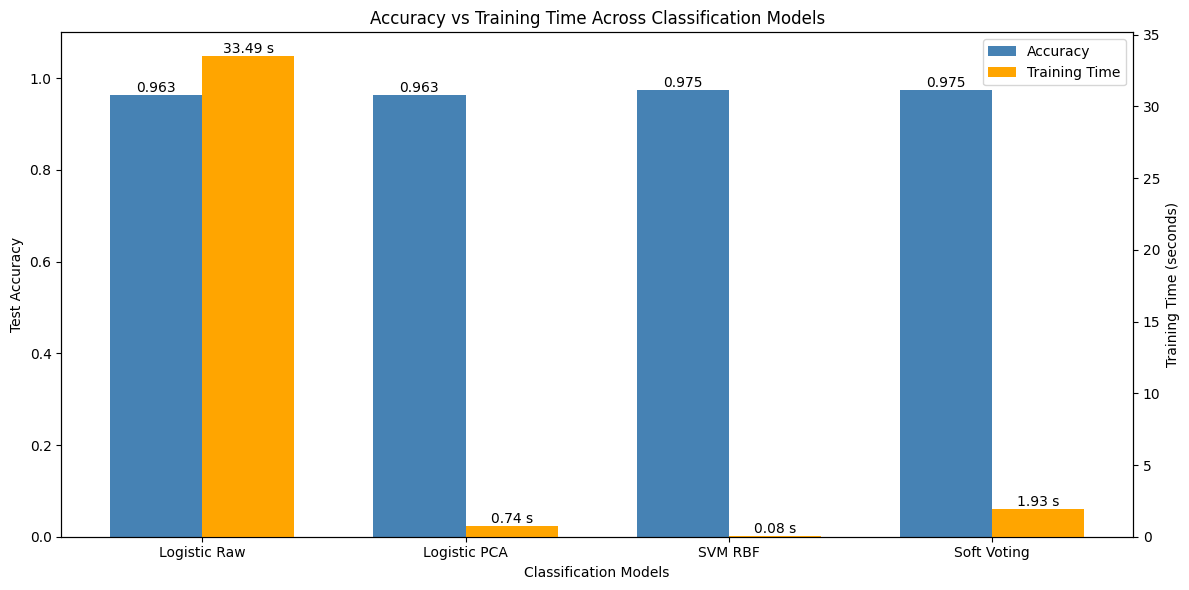

Best Accuracy Model: SVM RBF
Accuracy: 0.9750

Fastest Training Model: SVM RBF
Training Time: 0.0841 seconds


In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Define the four classification models
models = [
    "Logistic Raw",
    "Logistic PCA",
    "SVM RBF",
    "Soft Voting"
]

# Store accuracy results from previous tasks
accuracies = [
    raw_accuracy,
    pca_accuracy,
    svm_accuracy,
    ensemble_accuracy
]

# Store training times from previous tasks
training_times = [
    raw_time,
    pca_time,
    svm_time,
    ensemble_time
]

print("Model Performance Comparison\n")

for i in range(len(models)):
    print(f"{models[i]}")
    print(f"Accuracy: {accuracies[i]:.4f}")
    print(f"Training Time: {training_times[i]:.4f} seconds\n")

# Create positions for grouped bars
x = np.arange(len(models))
width = 0.35

# Create dual-axis bar chart
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot accuracy on the left axis
bars1 = ax1.bar(
    x - width / 2,
    accuracies,
    width,
    color="steelblue",
    label="Accuracy"
)

ax1.set_xlabel("Classification Models")
ax1.set_ylabel("Test Accuracy")
ax1.set_ylim(0, 1.1)

# Create a second axis for training time
ax2 = ax1.twinx()

# Plot training time on the right axis
bars2 = ax2.bar(
    x + width / 2,
    training_times,
    width,
    color="orange",
    label="Training Time"
)

ax2.set_ylabel("Training Time (seconds)")

ax1.bar_label(bars1, fmt="%.3f")
ax2.bar_label(bars2, fmt="%.2f s")

ax1.set_xticks(x)
ax1.set_xticklabels(models)
ax1.set_title("Accuracy vs Training Time Across Classification Models")

ax1.legend(
    [bars1, bars2],
    ["Accuracy", "Training Time"],
    loc="upper right"
)

plt.tight_layout()
plt.show()

# Identify the model with the highest accuracy
best_accuracy_index = np.argmax(accuracies)

# Identify the model with the fastest training time
fastest_index = np.argmin(training_times)

print("Best Accuracy Model:", models[best_accuracy_index])
print(f"Accuracy: {accuracies[best_accuracy_index]:.4f}")

print("\nFastest Training Model:", models[fastest_index])
print(f"Training Time: {training_times[fastest_index]:.4f} seconds")
